In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv(r"C:\Users\HP\auspify-ml-internship\data\netflix_clean.csv")
print(df.shape)

# class balance of the target
print(df["type"].value_counts(normalize=True))

# how many distinct values in each candidate feature?
candidates = ["director", "country", "release_year", "rating", "listed_in", "year_added", "month_added"]
print(df[candidates].nunique())

(8790, 14)
type
Movie      0.696928
TV Show    0.303072
Name: proportion, dtype: float64
director        4528
country           86
release_year      74
rating            14
listed_in        513
year_added        14
month_added       12
dtype: int64


In [2]:
print(df[df["type"] == "TV Show"]["listed_in"].head(10))
print(df[df["type"] == "Movie"]["listed_in"].head(10))

1     Crime TV Shows, International TV Shows, TV Act...
2                    TV Dramas, TV Horror, TV Mysteries
5                          British TV Shows, Reality TV
17                               Docuseries, Reality TV
18         British TV Shows, Crime TV Shows, Docuseries
20                                             Kids' TV
21                                             Kids' TV
22                                             Kids' TV
24    Crime TV Shows, International TV Shows, TV Act...
27    Crime TV Shows, Docuseries, International TV S...
Name: listed_in, dtype: object
0                                         Documentaries
3                    Children & Family Movies, Comedies
4      Dramas, Independent Movies, International Movies
6                                      Comedies, Dramas
7     Children & Family Movies, Comedies, Music & Mu...
8                          Dramas, International Movies
9            Children & Family Movies, Music & Musicals
10               

In [3]:
# one row per (title, genre)
genres = df[["type", "listed_in"]].copy()
genres["genre"] = genres["listed_in"].str.split(", ")
genres = genres.explode("genre")

# in how many types does each genre appear?
spread = genres.groupby("genre")["type"].nunique()
print("genres in both types:", (spread == 2).sum(), "out of", len(spread))
print(spread[spread == 2])

genres in both types: 0 out of 42
Series([], Name: type, dtype: int64)


In [4]:
from sklearn.model_selection import train_test_split

# target: 1 = TV Show, 0 = Movie
y = (df["type"] == "TV Show").astype(int)

# director -> yes/no
df["director_known"] = (df["director"] != "Unknown").astype(int)

features = ["rating", "country", "release_year", "year_added", "month_added", "director_known"]
X = df[features]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(7032, 6) (1758, 6)
0.30304323094425484 0.3031854379977247


In [5]:
print(X_train["country"].value_counts().head(10))
print("rows with a comma:", X_train["country"].str.contains(",").sum())

country
United States     2579
India              835
United Kingdom     518
Pakistan           348
Unknown            225
Canada             211
Japan              210
France             172
South Korea        165
Spain              145
Name: count, dtype: int64
rows with a comma: 0


In [6]:
top_countries = X_train["country"].value_counts().head(10).index

X_train = X_train.copy()
X_test = X_test.copy()
X_train["country"] = X_train["country"].where(X_train["country"].isin(top_countries), "Other")
X_test["country"] = X_test["country"].where(X_test["country"].isin(top_countries), "Other")

print(X_train["country"].value_counts())
print(X_test["country"].value_counts())

country
United States     2579
Other             1624
India              835
United Kingdom     518
Pakistan           348
Unknown            225
Canada             211
Japan              210
France             172
South Korea        165
Spain              145
Name: count, dtype: int64
country
United States     661
Other             384
India             222
United Kingdom    120
Pakistan           73
Unknown            62
Canada             60
South Korea        49
Japan              49
France             41
Spain              37
Name: count, dtype: int64


In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

cat_cols = ["rating", "country"]
num_cols = ["release_year", "year_added", "month_added", "director_known"]

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", "passthrough", num_cols),
])

X_train_enc = preprocessor.fit_transform(X_train)
X_test_enc = preprocessor.transform(X_test)

print(X_train_enc.shape, X_test_enc.shape)
print(preprocessor.get_feature_names_out()[:20])

(7032, 29) (1758, 29)
['cat__rating_G' 'cat__rating_NC-17' 'cat__rating_NR' 'cat__rating_PG'
 'cat__rating_PG-13' 'cat__rating_R' 'cat__rating_TV-14'
 'cat__rating_TV-G' 'cat__rating_TV-MA' 'cat__rating_TV-PG'
 'cat__rating_TV-Y' 'cat__rating_TV-Y7' 'cat__rating_TV-Y7-FV'
 'cat__rating_UR' 'cat__country_Canada' 'cat__country_France'
 'cat__country_India' 'cat__country_Japan' 'cat__country_Other'
 'cat__country_Pakistan']


In [8]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = {
    "Baseline (always Movie)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
}

results = []
for name, model in models.items():
    model.fit(X_train_enc, y_train)
    pred = model.predict(X_test_enc)
    results.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred),
        "f1": f1_score(y_test, pred),
    })

pd.DataFrame(results).round(3)

C:\Users\HP\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,model,accuracy,precision,recall,f1
0,Baseline (always Movie),0.697,0.000,0.000,0.000
1,Logistic Regression,0.949,0.933,0.895,0.914
2,Decision Tree,0.932,0.897,0.878,0.887
3,Random Forest,0.941,0.912,0.893,0.902


In [9]:
from sklearn.pipeline import Pipeline

print(pd.crosstab(df["director_known"], df["type"], normalize="index").round(3))

groups = {
    "rating": ["rating"],
    "country": ["country"],
    "release_year": ["release_year"],
    "date_added (year+month)": ["year_added", "month_added"],
    "director_known": ["director_known"],
}

rows = []
for name, cols in groups.items():
    keep_cat = [c for c in cat_cols if c not in cols]
    keep_num = [c for c in num_cols if c not in cols]
    pre = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), keep_cat),
        ("num", "passthrough", keep_num),
    ])
    pipe = Pipeline([("pre", pre), ("clf", LogisticRegression(max_iter=1000))])
    pipe.fit(X_train, y_train)
    rows.append({"dropped": name, "f1": f1_score(y_test, pipe.predict(X_test))})

pd.DataFrame(rows).round(3)

type            Movie  TV Show
director_known                
0               0.067    0.933
1               0.960    0.040


C:\Users\HP\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\Users\HP\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refe

,dropped,f1
0,rating,0.913
1,country,0.913
2,release_year,0.914
3,date_added (year+month),0.914
4,director_known,0.489


In [10]:
from sklearn.preprocessing import StandardScaler

def evaluate(num_used, label):
    out = []
    for name in ["Logistic Regression", "Decision Tree", "Random Forest"]:
        pre = ColumnTransformer([
            ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
            ("num", StandardScaler(), num_used),
        ])
        pipe = Pipeline([("pre", pre), ("clf", models[name])])
        pipe.fit(X_train, y_train)
        pred = pipe.predict(X_test)
        out.append({
            "features": label,
            "model": name,
            "accuracy": accuracy_score(y_test, pred),
            "f1": f1_score(y_test, pred),
        })
    return pd.DataFrame(out)

with_dir = evaluate(["release_year", "year_added", "month_added", "director_known"], "with director_known")
without_dir = evaluate(["release_year", "year_added", "month_added"], "without director_known")

pd.concat([with_dir, without_dir]).round(3)

,features,model,accuracy,f1
0,with director_known,Logistic Regression,0.949,0.914
1,with director_known,Decision Tree,0.932,0.887
2,with director_known,Random Forest,0.941,0.902
0,without director_known,Logistic Regression,0.771,0.498
1,without director_known,Decision Tree,0.769,0.586
2,without director_known,Random Forest,0.768,0.591


In [11]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import confusion_matrix, classification_report

num_all = ["release_year", "year_added", "month_added", "director_known"]
pre = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", StandardScaler(), num_all),
])
best = Pipeline([("pre", pre), ("clf", LogisticRegression(max_iter=1000))])

# 5-fold cross-validation on the training set
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(best, X_train, y_train, cv=cv, scoring="f1")
print("CV F1 per fold:", scores.round(3))
print("mean:", scores.mean().round(3), "std:", scores.std().round(3))

# final check on the test set
best.fit(X_train, y_train)
pred = best.predict(X_test)
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred, target_names=["Movie", "TV Show"]))

CV F1 per fold: [0.911 0.924 0.925 0.919 0.926]
mean: 0.921 std: 0.006
[[1191   34]
 [  56  477]]
              precision    recall  f1-score   support

       Movie       0.96      0.97      0.96      1225
     TV Show       0.93      0.89      0.91       533

    accuracy                           0.95      1758
   macro avg       0.94      0.93      0.94      1758
weighted avg       0.95      0.95      0.95      1758



In [12]:
errors = X_test[(pred == 0) & (y_test == 1)]   # TV Shows predicted as Movie
print("share with a known director:", errors["director_known"].mean().round(3))
print(errors["rating"].value_counts().head(5))

share with a known director: 1.0
rating
TV-MA    33
TV-14    11
TV-PG     5
TV-Y7     4
TV-Y      2
Name: count, dtype: int64


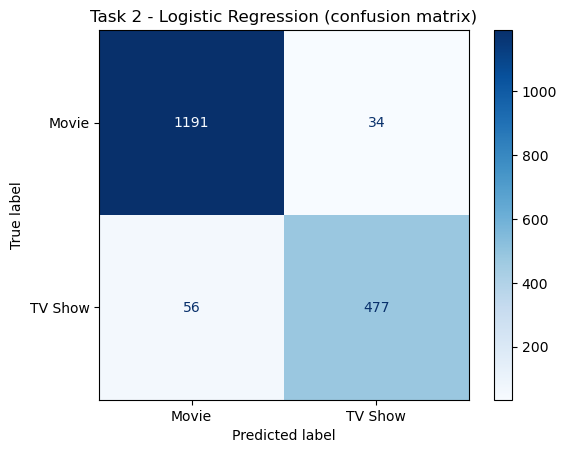

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=["Movie", "TV Show"], cmap="Blues"
)
plt.title("Task 2 - Logistic Regression (confusion matrix)")
plt.savefig("../outputs/task2_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()